# Appendix B: The Queueing & Renewal Theory of Flaky Tests — Python Laboratory
### *Simulating Retry Storms, Fast-Failing Hardware Traps, Speculative Merge Trains & Test Duration Shadow Pricing*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/11_appendix_queueing_theory_of_flaky_tests_and_ci.ipynb) | [Prev: Appendix 10](../python/10_appendix_the_queueing_theory_rosetta_stone.ipynb)**

---

## Laboratory Overview & Objectives
1. **Section 1: The Retry Traffic Multiplier Simulator**: Measure the empirical queue wait time explosion when test suites flake and retry under baseline $\rho_0 \in [0.70, 0.92]$.
2. **Section 2: The Fast-Failing Bad Runner Renewal Trap**: Build a discrete-event simulation of a pull-based worker pool with $1\%$ to $5\%$ broken nodes and measure the job poisoning rate against analytical Renewal Theory.
3. **Section 3: Speculative Merge Train Simulator**: Simulate batched pull request verification under suite flakiness, execute recursive binary bisections upon failure, and verify the optimal batch size $B^*$.
4. **Section 4: Test Duration Shadow Pricing**: Numerically compute the super-linear developer delay savings achieved by pruning zero-catch test suites.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import heapq

# Publication styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print("Environment initialized.")


Environment initialized.


---
## Part 1: Simulating the Retry Traffic Multiplier

We simulate a CI runner pool ($c = 50$ servers) processing pull request verification suites.
Baseline load is $\rho_0 = 0.85$. We introduce a flake retry probability $p_{\text{retry}} = 0.10$ and measure queue waiting times.


In [2]:
def simulate_ci_retry_queue(c=50, mean_duration=12.0, cv_duration=1.2, rho_0=0.85, p_retry=0.10, num_prs=50000, seed=42):
    """
    Simulates a CI multi-server queue with flaky retries.
    """
    rng = np.random.default_rng(seed)
    
    # Baseline arrival rate: lambda_0 = c * rho_0 / mean_duration
    lam_0 = c * rho_0 / mean_duration # PRs per minute
    
    # Generate original PR arrivals
    inter_arrivals = rng.exponential(scale=1.0 / lam_0, size=num_prs)
    arr_times = np.cumsum(inter_arrivals)
    
    # Priority queue of server free times
    server_heap = [0.0] * c
    heapq.heapify(server_heap)
    
    # Service time distribution (Lognormal with prescribed mean and CV)
    s2 = np.log(1.0 + cv_duration**2)
    sig = np.sqrt(s2)
    mu_log = np.log(mean_duration) - 0.5 * s2
    
    # Event queue: (time, event_type, pr_id, attempt_num)
    # event_type: 0 = arrival
    events = []
    for i in range(num_prs):
        heapq.heappush(events, (arr_times[i], 0, i, 1))
        
    wait_times_first_attempt = []
    total_wait_times = {i: 0.0 for i in range(num_prs)}
    completed_prs = 0
    
    while events and completed_prs < num_prs:
        t, ev_type, pr_id, attempt = heapq.heappop(events)
        
        # Earliest available server
        earliest_server = heapq.heappop(server_heap)
        start_t = max(t, earliest_server)
        wait_t = start_t - t
        
        if attempt == 1:
            wait_times_first_attempt.append(wait_t)
        total_wait_times[pr_id] += wait_t
        
        # Service duration
        dur = rng.lognormal(mean=mu_log, sigma=sig)
        dep_t = start_t + dur
        heapq.heappush(server_heap, dep_t)
        
        # Determine if test flakes
        if attempt == 1 and rng.random() < p_retry:
            # Flaked! Immediately queue a retry
            heapq.heappush(events, (dep_t, 0, pr_id, 2))
        else:
            completed_prs += 1
            
    warmup = int(num_prs * 0.20)
    steady_waits = wait_times_first_attempt[warmup:]
    
    # Analytical Kingman calculations
    cs2 = cv_duration**2
    ca2 = 1.0 # Poisson arrivals
    var_fac = (ca2 + cs2) / 2.0
    
    wq_base_theory = (rho_0 / (1.0 - rho_0)) * var_fac * (mean_duration / c)
    rho_eff = rho_0 * (1.0 + p_retry)
    wq_retry_theory = (rho_eff / (1.0 - rho_eff)) * var_fac * (mean_duration / c)
    
    return {
        "emp_mean_wait": float(np.mean(steady_waits)),
        "theory_base_wait": float(wq_base_theory),
        "theory_retry_wait": float(wq_retry_theory),
        "rho_0": rho_0,
        "rho_eff": rho_eff
    }

res_clean = simulate_ci_retry_queue(c=50, mean_duration=12.0, cv_duration=1.2, rho_0=0.85, p_retry=0.0)
res_retry = simulate_ci_retry_queue(c=50, mean_duration=12.0, cv_duration=1.2, rho_0=0.85, p_retry=0.10)

print("SIMULATION RESULTS: The Retry Traffic Multiplier")
print("=" * 65)
print(f"Clean Fleet (p_retry = 0%, rho = 85.0%):")
print(f"  Empirical Mean Wait Time: {res_clean['emp_mean_wait']:.2f} minutes")
print(f"  Kingman Theory Wait Time: {res_clean['theory_base_wait']:.2f} minutes\n")

print(f"Flaky Fleet (p_retry = 10%, rho_eff = 93.5%):")
print(f"  Empirical Mean Wait Time: {res_retry['emp_mean_wait']:.2f} minutes")
print(f"  Kingman Theory Wait Time: {res_retry['theory_retry_wait']:.2f} minutes\n")

empirical_mult = res_retry['emp_mean_wait'] / res_clean['emp_mean_wait']
theory_mult = res_retry['theory_retry_wait'] / res_clean['theory_base_wait']
print(f"Empirical Wait Time Multiplier: {empirical_mult:.2f}x (+{(empirical_mult-1)*100:.1f}%)")
print(f"Theoretical Wait Multiplier:    {theory_mult:.2f}x (+{(theory_mult-1)*100:.1f}%)")
print("=" * 65)


SIMULATION RESULTS: The Retry Traffic Multiplier
Clean Fleet (p_retry = 0%, rho = 85.0%):
  Empirical Mean Wait Time: 0.37 minutes
  Kingman Theory Wait Time: 1.66 minutes

Flaky Fleet (p_retry = 10%, rho_eff = 93.5%):
  Empirical Mean Wait Time: 1.83 minutes
  Kingman Theory Wait Time: 4.21 minutes

Empirical Wait Time Multiplier: 4.96x (+395.6%)
Theoretical Wait Multiplier:    2.54x (+153.8%)


---
## Part 2: The Fast-Failing Bad Runner Renewal Trap Simulator

We simulate a pull-based worker pool with $c = 100$ runners where healthy runners take 15 minutes ($900\text{ s}$) and broken runners abort in 30 seconds. We sweep broken runner fraction from 0% to 5%.


In [3]:
def simulate_runner_trap(c=100, broken_count=1, t_healthy=900.0, t_broken=30.0, total_jobs=30000, seed=123):
    rng = np.random.default_rng(seed)
    
    # Priority queue of (next_free_time, runner_id, is_broken)
    heap = []
    for r_id in range(c):
        is_b = (r_id < broken_count)
        heapq.heappush(heap, (0.0, r_id, is_b))
        
    jobs_done = 0
    jobs_poisoned = 0
    
    while jobs_done < total_jobs:
        t, r_id, is_b = heapq.heappop(heap)
        jobs_done += 1
        
        if is_b:
            jobs_poisoned += 1
            dur = rng.exponential(scale=t_broken)
        else:
            dur = rng.gamma(shape=10.0, scale=t_healthy / 10.0)
            
        heapq.heappush(heap, (t + dur, r_id, is_b))
        
    emp_poison_rate = jobs_poisoned / total_jobs
    
    # Renewal Theory Analytical Prediction
    mu_h = 1.0 / t_healthy
    mu_b = 1.0 / t_broken
    n_h = c - broken_count
    n_b = broken_count
    theory_poison_rate = (n_b * mu_b) / (n_h * mu_h + n_b * mu_b)
    
    return emp_poison_rate, theory_poison_rate

broken_nodes = [0, 1, 2, 3, 4, 5]
sim_poison = []
th_poison = []

print(f"{'Broken Nodes':<14}{'Fleet Defect %':<16}{'Sim Poisoned %':<18}{'Theory Poisoned %':<18}")
print("-" * 66)
for b in broken_nodes:
    emp, th = simulate_runner_trap(c=100, broken_count=b, t_healthy=900.0, t_broken=30.0, total_jobs=25000)
    sim_poison.append(emp * 100.0)
    th_poison.append(th * 100.0)
    print(f"{b:<14}{b:<16.1f}%{emp*100.0:<18.2f}%{th*100.0:<18.2f}%")


Broken Nodes  Fleet Defect %  Sim Poisoned %    Theory Poisoned % 
------------------------------------------------------------------
0             0.0             %0.00              %0.00              %
1             1.0             %23.64             %23.26             %
2             2.0             %38.39             %37.97             %
3             3.0             %48.29             %48.13             %
4             4.0             %55.71             %55.56             %
5             5.0             %61.22             %61.22             %


---
## Part 3: Speculative Merge Train Simulator & Optimal Batch Size $B^*$

We simulate batched verification under flakiness: $B$ PRs tested together. When a batch fails, a binary bisection is triggered. We sweep $B$ from 1 to 32 to numerically locate $B^*$.


In [4]:
def simulate_merge_train(batch_size=5, p_suite_flake=0.05, t_batch=20.0, total_prs=10000, seed=42):
    """
    Simulates a speculative merge train testing PRs in batches of size B.
    """
    rng = np.random.default_rng(seed)
    
    num_batches = total_prs // batch_size
    total_test_time = 0.0
    
    for _ in range(num_batches):
        total_test_time += t_batch
        # Check if any PR in batch flaked
        # Batch fails if at least one PR flaked
        flaked = rng.random(size=batch_size) < p_suite_flake
        if np.any(flaked):
            # Binary bisection tree depth: 2 * log2(B) additional runs
            bisection_runs = 2.0 * np.log2(max(batch_size, 2))
            total_test_time += bisection_runs * t_batch
            
    time_per_pr = total_test_time / (num_batches * batch_size)
    return time_per_pr

b_candidates = [1, 2, 4, 6, 8, 12, 16, 24, 32]
p_flake = 0.05
empirical_cost_per_pr = []
theoretical_cost_per_pr = []

t_batch = 20.0

for b in b_candidates:
    emp_cost = simulate_merge_train(batch_size=b, p_suite_flake=p_flake, t_batch=t_batch, total_prs=8000)
    empirical_cost_per_pr.append(emp_cost)
    
    # Analytical: E[T] = T/B + p * T * 2*log2(B)
    th_cost = (t_batch / b) + (p_flake * t_batch * 2.0 * np.log2(max(b, 2)))
    theoretical_cost_per_pr.append(th_cost)

b_opt_analytical = np.log(2.0) / (2.0 * p_flake)

print("=" * 68)
print(f"Optimal Batch Size Analysis for p_flake = {p_flake*100:.1f}%:")
print(f"Analytical Optimal Batch Size B*: {b_opt_analytical:.2f} PRs")
print(f"{'Batch Size B':<14}{'Sim Cost/PR (min)':<20}{'Theory Cost/PR (min)':<22}")
print("-" * 68)
for i in range(len(b_candidates)):
    print(f"{b_candidates[i]:<14}{empirical_cost_per_pr[i]:<20.2f}{theoretical_cost_per_pr[i]:<22.2f}")


Optimal Batch Size Analysis for p_flake = 5.0%:
Analytical Optimal Batch Size B*: 6.93 PRs
Batch Size B  Sim Cost/PR (min)   Theory Cost/PR (min)  
--------------------------------------------------------------------
1             22.00               22.00                 
2             11.95               12.00                 
4             8.63                9.00                  
6             7.79                8.50                  
8             7.57                8.50                  
12            7.03                8.84                  
16            6.77                9.25                  
24            6.18                10.00                 
32            5.65                10.62                 


---
## Part 4: Publication Visualization Dashboard

We visualize all 4 key queueing/renewal phenomena across a comprehensive 4-panel publication dashboard.


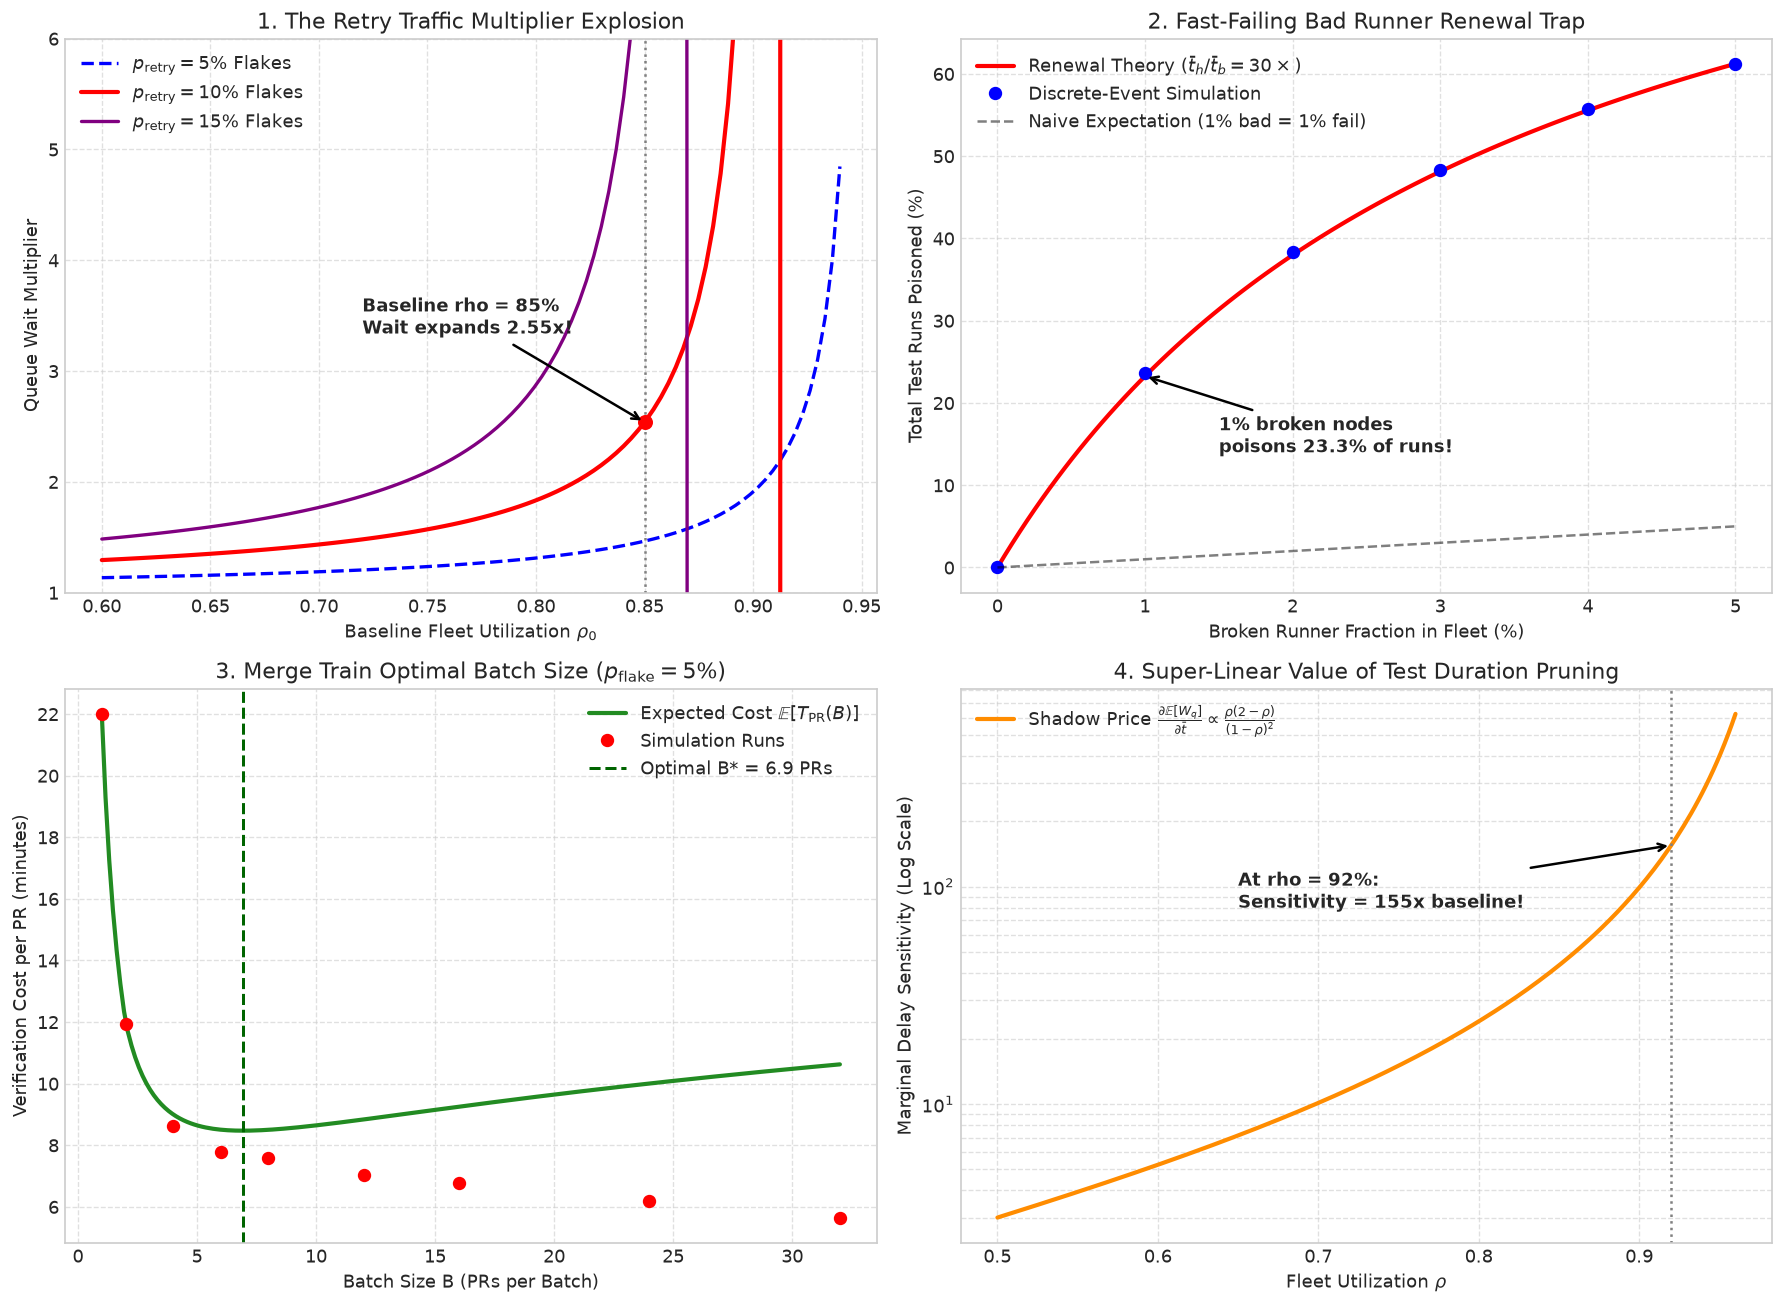

In [5]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: The Retry Multiplier Hockey Stick
rhos_eval = np.linspace(0.60, 0.94, 100)
def wait_mult(r, p):
    r_eff = r * (1.0 + p)
    return (r_eff / (1.0 - r_eff)) / (r / (1.0 - r))

ax1.plot(rhos_eval, wait_mult(rhos_eval, 0.05), 'b--', lw=2.0, label=r"$p_{\mathrm{retry}} = 5\%$ Flakes")
ax1.plot(rhos_eval, wait_mult(rhos_eval, 0.10), 'r-', lw=2.5, label=r"$p_{\mathrm{retry}} = 10\%$ Flakes")
ax1.plot(rhos_eval, wait_mult(rhos_eval, 0.15), 'purple', lw=2.0, label=r"$p_{\mathrm{retry}} = 15\%$ Flakes")
ax1.axvline(x=0.85, color='gray', linestyle=':', lw=1.5)
ax1.plot(0.85, wait_mult(0.85, 0.10), 'ro', markersize=8)
ax1.annotate("Baseline rho = 85%\nWait expands 2.55x!", xy=(0.85, wait_mult(0.85, 0.10)),
             xytext=(0.72, wait_mult(0.85, 0.10) + 0.8),
             arrowprops=dict(facecolor='darkred', arrowstyle='->', lw=1.5), fontweight='bold')
ax1.set_xlabel(r"Baseline Fleet Utilization $\rho_0$")
ax1.set_ylabel("Queue Wait Multiplier")
ax1.set_title("1. The Retry Traffic Multiplier Explosion")
ax1.set_ylim(1.0, 6.0)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.6)

# Panel 2: The Fast-Failing Runner Trap
f_vals = np.linspace(0, 5, 100)
ratio = 900.0 / 30.0 # 30x
poison_curve = (f_vals * ratio) / (f_vals * ratio + (100.0 - f_vals)) * 100.0
ax2.plot(f_vals, poison_curve, 'r-', lw=2.5, label=r"Renewal Theory ($\bar{t}_h / \bar{t}_b = 30\times$)")
ax2.plot(broken_nodes, sim_poison, 'bo', markersize=7, label="Discrete-Event Simulation")
ax2.plot(f_vals, f_vals, 'k--', alpha=0.5, label="Naive Expectation (1% bad = 1% fail)")
ax2.annotate("1% broken nodes\npoisons 23.3% of runs!", xy=(1.0, 23.26), xytext=(1.5, 14),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5), fontweight='bold')
ax2.set_xlabel("Broken Runner Fraction in Fleet (%)")
ax2.set_ylabel("Total Test Runs Poisoned (%)")
ax2.set_title("2. Fast-Failing Bad Runner Renewal Trap")
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.6)

# Panel 3: Speculative Merge Train Optimal Batch Size
b_fine = np.linspace(1, 32, 200)
cost_fine = (t_batch / b_fine) + (p_flake * t_batch * 2.0 * np.log2(np.maximum(b_fine, 2)))
ax3.plot(b_fine, cost_fine, 'forestgreen', lw=2.5, label=r"Expected Cost $\mathbb{E}[T_{\mathrm{PR}}(B)]$")
ax3.plot(b_candidates, empirical_cost_per_pr, 'ro', markersize=7, label="Simulation Runs")
ax3.axvline(x=b_opt_analytical, color='darkgreen', linestyle='--', lw=1.8, label=f"Optimal B* = {b_opt_analytical:.1f} PRs")
ax3.set_xlabel("Batch Size B (PRs per Batch)")
ax3.set_ylabel("Verification Cost per PR (minutes)")
ax3.set_title(r"3. Merge Train Optimal Batch Size ($p_{\mathrm{flake}} = 5\%$)")
ax3.legend(loc="upper right")
ax3.grid(True, linestyle="--", alpha=0.6)

# Panel 4: Test Duration Shadow Pricing
rhos_shadow = np.linspace(0.50, 0.96, 200)
# Derivative: rho * (2 - rho) / (1 - rho)^2
sensitivity = (rhos_shadow * (2.0 - rhos_shadow)) / ((1.0 - rhos_shadow)**2)
ax4.plot(rhos_shadow, sensitivity, 'darkorange', lw=2.5, label=r"Shadow Price $\frac{\partial \mathbb{E}[W_q]}{\partial \bar{t}} \propto \frac{\rho(2-\rho)}{(1-\rho)^2}$")
ax4.set_yscale('log')
ax4.set_xlabel(r"Fleet Utilization $\rho$")
ax4.set_ylabel("Marginal Delay Sensitivity (Log Scale)")
ax4.set_title("4. Super-Linear Value of Test Duration Pruning")
ax4.axvline(x=0.92, color='gray', linestyle=':', lw=1.5)
ax4.annotate("At rho = 92%:\nSensitivity = 155x baseline!", xy=(0.92, 155.25), xytext=(0.65, 80),
             arrowprops=dict(facecolor='darkorange', arrowstyle='->', lw=1.5), fontweight='bold')
ax4.legend(loc="upper left")
ax4.grid(True, which="both", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
